##### Master Degree in Computer Science and Data Science for Economics and Health

# From pre-training to a usable model: fine-tuning and LoRA

### Prof. Alfio Ferrara

## Introduction

A language model that has been pre-trained on a lot of text knows a lot, but it is not yet the model that we need: it has not been trained on *our* task, in *our* format, on *our* data. The simplest answer is **fine-tuning**: we continue the training of the pre-trained network on examples of the new task, and all the weights can change. It works, and it is how BERT was used when it appeared (L1.3). But for a network with billions of parameters it has a cost, and this cost is the reason for the family of methods that this notebook introduces, the **parameter-efficient fine-tuning**, and in particular **LoRA** (*Low-Rank Adaptation*, Hu et al., 2021).

The questions of this notebook:

1. **Step 1**: the problem. A network pre-trained on texts in three languages and on one translation cannot do a translation that it has never seen. We see what it knows and what it does not;
2. **Step 2**: fine-tuning of all the weights. It works with very few examples, where the same network trained from scratch fails; but we see what it costs, and what it makes us lose;
3. **Step 3**: the idea of LoRA. The fine-tuning changes each matrix $W$ into $W + \Delta W$; LoRA asks that $\Delta W$ be the product of two thin matrices. We write the layer, count the parameters, and look at the changes that the full fine-tuning has made to see whether this request is reasonable;
4. **Step 4**: we train the thin matrices. The learning rate, the rank and the choice of the matrices, compared with the full fine-tuning;
5. **Step 5**: one network and its adapter. Switching the adapter off and on, merging it into the matrices, and what the storage costs;
6. **Step 6**: what LoRA costs in a real network, counted on the matrices of GPT-2, and the limits of what we have shown.

The networks that take time to train are saved **outside the repository**, in `models/L1.5/` (the function `trained_network` below): if the file is there the network is loaded, otherwise it is trained and saved. The first run, which trains everything, took about ten minutes on our machine (9 min 37 s); the next ones take about a minute and a half. We trained all the networks again, from scratch, on the same machine, and obtained the same numbers that you see below; on another machine they could differ in the last digits. If you change the data, the settings or `tinylm.py`, delete the folder.

As in the previous notebooks, the toy world has its advantages (we can read everything and train in seconds) and its limits: our network has 60,000 parameters and its matrices are 32 numbers wide, so the savings of LoRA that we can measure are much smaller than those of a real model. We say it each time it matters.

In [1]:
import os
import re
import copy
import time
import inspect
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from nlp import toyworld, tinylm

warnings.filterwarnings("ignore", category=FutureWarning)

CACHE = "../../models/L1.5"                  # outside the repository: the trained networks, saved only to save time

def trained_network(name, train):
    # the network saved under `name` in CACHE if the file exists; otherwise `train()` trains it and it is saved there
    start = time.time()
    model, loaded = tinylm.cached(f"{CACHE}/{re.sub('[^a-z0-9]+', '-', name.lower()).strip('-')}.pt", train)
    print(f"{name}: {model.n_parameters():,} parameters, {tinylm.n_trainable(model):,} trained, " + ("loaded from the cache" if loaded else f"trained in {time.time() - start:.0f} s"))
    return model

## Step 1: a pre-trained network and a task it has never seen

> **A simple example.** During the pre-training the network has read many documents of our world written in three languages, **A** (`anna lives in milan .`), **B** (`anna zuszu baris .`) and **C**, where the same facts are written with other words. It has also seen many *pairs* A → B, that is, it has learned to continue `anna lives in milan . <sep>` with the same sentence in B. What it has never seen is a pair A → C. Now we want it to continue `anna lives in milan . <sep>` with the sentence in C.
>
> The question of this section is: what does a pre-trained network do with a task that is a *small variation* of one it knows? The intuition is that it has all the pieces, the words of A, the words of C and the habit of writing a translation after `<sep>`, but not the connection between A and C, and we expect to see it write something that looks like a translation and is not the right one.

In [2]:
LANGUAGE_B, LANGUAGE_C = toyworld.make_language_b(0), toyworld.make_language_b(7)     # two languages, same word order, other words

def make_world(seed):
    return toyworld.ToyWorld(toyworld.WorldConfig(n_people=12, seed=seed), language_b=LANGUAGE_B, extra_languages={"C": LANGUAGE_C})

worlds = [make_world(k) for k in range(20)]           # the worlds of the pre-training: the same people, other facts
new_world = make_world(50)                            # a world that the networks never see in training, to test
vocab = worlds[0].vocabulary(("A", "B", "C"))         # one vocabulary for the three languages
SEP = vocab.encode(["<sep>"])[0]
print(f"{len(vocab)} words in the vocabulary\n")

for language in "ABC":
    print(language, " ".join(new_world.document(3, n_people=1, n_facts=3, language=language)))

117 words in the vocabulary

A <s> mario likes green . he lives in rome . he drinks tea . </s>
B <s> sirkon duzul mario . pumus zuszu derli . pumus datol dinsos . </s>
C <s> filtos sirkis mario . zinfi ralvir ronzin . zinfi tekel lulpir . </s>


The same document (the same facts, the same pronouns) in the three languages. The languages B and C have the same word order and different words: this is what makes C a *small variation* of B.

The **pre-training** data are four sets of texts, all taken from the 20 worlds: 10,000 documents in A, 10,000 in B, 10,000 in C, and 10,000 pairs A → B written as `<s> source <sep> target </s>`. The network is the decoder-only network of L1.4 (4 blocks, $d = 32$, 2 heads) and the loss is the usual one, the next word at every position. After this the network has seen documents in C, but never a pair with C as target.

In [3]:
def documents(language, n, seed, from_worlds=worlds):
    return [d for k, w in enumerate(from_worlds) for d in w.documents(seed + k, n // len(from_worlds), language=language)]

def pairs(target, n, seed, from_worlds=worlds):
    # <s> source in A <sep> target </s>; the <s> and </s> of the two documents are dropped
    return [["<s>"] + a[1:-1] + ["<sep>"] + b[1:-1] + ["</s>"]
            for k, w in enumerate(from_worlds) for a, b in w.translation(seed + k, n // len(from_worlds), target=target)]

def as_tensor(texts, length=55):
    t = torch.tensor(vocab.batch(texts))
    return F.pad(t, (0, length - t.shape[1]))

pretraining = torch.cat([as_tensor(documents(language, 10000, 100 + i)) for i, language in enumerate("ABC")] + [as_tensor(pairs("B", 10000, 500))])
print(pretraining.shape[0], "texts of", pretraining.shape[1], "positions")

def pretrain(seed):
    return tinylm.fit_lm(pretraining, seed=seed, steps=4000, batch_size=64, model_class=tinylm.DecoderOnly, vocabulary_size=len(vocab), sep=SEP)

SEEDS = (0, 1)
bases = [trained_network(f"pre-trained seed {s}", lambda s=s: pretrain(s)) for s in SEEDS]

40000 texts of 55 positions
pre-trained seed 0: 60,021 parameters, 60,021 trained, loaded from the cache
pre-trained seed 1: 60,021 parameters, 60,021 trained, loaded from the cache


We test the networks on pairs of a **new world**, the one they have never seen, and we count two things: the sentences written exactly right, and the words right at the right place. We test A → B (what the network was trained on) and A → C (what it was not). We also measure how well it writes plain documents in A (the *plain-text loss*, the usual next-word loss on documents without any `<sep>`), because we will need to know what happens to this ability.

In [4]:
test_b = as_tensor(pairs("B", 1000, 700, [new_world]))
test_c = as_tensor(pairs("C", 1000, 710, [new_world]))
plain_a = as_tensor(documents("A", 1000, 900))

def evaluate(model):
    sent_c, words_c = tinylm.completion_accuracy(model, test_c, SEP)
    sent_b, words_b = tinylm.completion_accuracy(model, test_b, SEP)
    return {"A→C sentences": sent_c, "A→C words": words_c, "A→B sentences": sent_b, "plain-text loss": tinylm.lm_loss(model, plain_a)}

print(pd.DataFrame([evaluate(m) for m in bases], index=[f"seed {s}" for s in SEEDS]).round(3).to_string())

written = tinylm.complete(bases[0], test_c[:1], SEP)[0]
start = int((test_c[0] == SEP).int().argmax())
print("\nsource   ", " ".join(vocab.decode(test_c[0][:start + 1].tolist())))
print("expected ", " ".join(vocab.decode(test_c[0][start + 1:].tolist(), skip_special=True)))
print("written  ", " ".join(vocab.decode(written[start + 1:].tolist(), skip_special=True)))

        A→C sentences  A→C words  A→B sentences  plain-text loss
seed 0            0.0      0.407          0.995            0.898
seed 1            0.0      0.408          0.993            0.891

source    <s> carlo is a farmer . carlo likes red . he lives in milan . marta lives in genoa . she is a teacher . marta drinks juice . <sep>
expected  zeran carlo bellen . serbol sirkis carlo . zinfi ralvir talpa . marta ralvir gingu . lerzer sunna bellen . marta dilken lulpir .
written   parpol carlo vudas . lisval duzul carlo . pumus zuszu baris . marta zuszu toslu . vosgo lirnes vudas . marta nunto dinsos .


Both networks (the two seeds) do the translation they were trained on, A → B: 99.5% and 99.3% of the sentences exactly right. For A → C they get **no sentence right** (0.0%), and the words right at the right place are 40.7% and 40.8%. This share is almost entirely the words that A, B and C have in common: in the targets in C the names and the full stops are 36.8% of the words, and the network of seed 0 writes all of them right (36.7%), so the other words right are about four points out of a hundred.

The example shows the rest. The network of seed 0 reads the source and, after `<sep>`, writes a text that has the right structure, the names of the right people in the right places, but with the words of B (`duzul`, `zuszu` are words of B that we saw above): over the whole test set, 61.7% of the words that it writes after `<sep>` are words of B, none is a word of C, and the remaining 38.3% are words that belong to neither language, the names and the full stops among them. It does what it has learned to do after a `<sep>`, which is to translate to B, and it does not use its knowledge of C. The plain-text loss (0.90 and 0.89) is the reference for what follows.

## Step 2: fine-tuning all the weights

> **A simple example.** We show the network 300 pairs `anna lives in milan . <sep> ...` with the sentence in C, and we let *every* weight change a little, for a thousand steps, with the same loss as before but counted only on the words that follow `<sep>`. After this the network should continue the sources with the sentence in C.
>
> The question of this section is: how many examples does the adaptation need, and what does it cost and what does it make us lose? The intuition is that 300 examples are very few for a network that learns a translation from nothing, but are enough for one that already knows the words and the habit of translating, and that all the weights change together: so the network that writes C after `<sep>` can no longer be the one that writes B, because the two tasks have exactly the same input.

In [5]:
finetuning_data = as_tensor(pairs("C", 300, 300))          # 15 pairs from each of the 20 worlds
print(finetuning_data.shape[0], "pairs A → C")

def full_fine_tuning(base, seed):
    return tinylm.fine_tune(copy.deepcopy(base), finetuning_data, SEP, steps=1000, lr=1e-3, seed=seed)

def from_scratch(seed):
    return tinylm.fit_continuation(finetuning_data, SEP, seed=seed, steps=1000, lr=3e-3, vocabulary_size=len(vocab))

fulls = [trained_network(f"full fine-tuning seed {s}", lambda s=s: full_fine_tuning(bases[s], s)) for s in SEEDS]
scratch = [trained_network(f"from scratch seed {s}", lambda s=s: from_scratch(s)) for s in SEEDS]

300 pairs A → C
full fine-tuning seed 0: 60,021 parameters, 60,021 trained, loaded from the cache
full fine-tuning seed 1: 60,021 parameters, 60,021 trained, loaded from the cache
from scratch seed 0: 60,021 parameters, 60,021 trained, loaded from the cache
from scratch seed 1: 60,021 parameters, 60,021 trained, loaded from the cache


In [6]:
rows = {"pre-trained, no fine-tuning": bases, "pre-trained + full fine-tuning": fulls, "from scratch, the same 300 pairs": scratch}
table = pd.DataFrame({name: pd.DataFrame([evaluate(m) for m in models]).mean() for name, models in rows.items()}).T
table.insert(0, "trainable parameters", [models[0].n_parameters() for models in rows.values()])
print("mean of 2 seeds")
table.style.format({"trainable parameters": "{:,.0f}", "A→C sentences": "{:.3f}", "A→C words": "{:.3f}", "A→B sentences": "{:.3f}", "plain-text loss": "{:.2f}"})

mean of 2 seeds


,trainable parameters,A→C sentences,A→C words,A→B sentences,plain-text loss
"pre-trained, no fine-tuning","60,021",0.000,0.408,0.994,0.89
pre-trained + full fine-tuning,"60,021",0.858,0.985,0.000,1.16
"from scratch, the same 300 pairs","60,021",0.084,0.836,0.000,9.06


Fine-tuning works, and with very few examples. After 1,000 steps on 300 pairs the pre-trained network writes the sentence in C exactly right in 93.1% (seed 0) and 78.4% (seed 1) of the cases of a world it has never seen, and 99.6% and 97.4% of the words; the same network trained **from scratch** on the same 300 pairs gets 3.4% and 13.4% of the sentences (and 81.3% and 85.9% of the words, since it has learned the common words). The pre-training is what makes 300 pairs enough. With more pairs the gap closes: in a trial of ours with 2,000 pairs and 1,500 steps (two seeds, not part of this notebook) the network from scratch reached 99.6% and 99.7%, so the advantage is in the *few* examples.

There is a difference between the two seeds (93.1% against 78.4%): this is why we use more than one, and why we do not give weight to differences of a few points between single runs.

The table also shows what is lost. The accuracy on A → B falls to zero in both networks: the input is the same (`source <sep>`) and the network now answers with C. The **plain-text loss** goes from 0.89 to 1.16 (1.09 and 1.23 in the two seeds): the network writes plain documents worse than before, although it was never asked to forget them, because all its weights have changed for another task. In the network from scratch this loss is 9.06 since it never saw a plain document, and this tells us that 1.16 is still a small damage, not a collapse. The question for the next steps is whether we can keep the new behavior and not damage the old one.

The accuracy is not the only price. To train a network with the usual optimizer (AdamW) the memory must hold, for each parameter, the parameter itself, its gradient and two running averages of the gradient that the optimizer keeps. And a full fine-tuning produces a **new copy** of the network for each task.

In [7]:
n = bases[0].n_parameters()
print(f"our network: {n:,} parameters; with parameter, gradient and two averages: {4 * n:,} numbers, {16 * n / 1e6:.1f} MB (float32), and one copy of {4 * n / 1e6:.2f} MB per task")
for name, size in (("GPT-2 small (L1.4)", 124_439_808), ("a model with 7 billion parameters", 7_000_000_000)):
    print(f"{name}: {size:,} parameters, {16 * size / 1e9:,.1f} GB to train in float32, and {4 * size / 1e9:,.1f} GB for each copy saved for a task")

our network: 60,021 parameters; with parameter, gradient and two averages: 240,084 numbers, 1.0 MB (float32), and one copy of 0.24 MB per task
GPT-2 small (L1.4): 124,439,808 parameters, 2.0 GB to train in float32, and 0.5 GB for each copy saved for a task
a model with 7 billion parameters: 7,000,000,000 parameters, 112.0 GB to train in float32, and 28.0 GB for each copy saved for a task


The numbers come from a simple count: 4 numbers of 4 bytes for each parameter (float32, with no tricks to save memory). In our network they are small (one megabyte), and this is the limit of the toy that we have to remember: for GPT-2 small the training needs about 2 GB and each copy kept for a task takes 0.5 GB; for a model of 7 billion parameters 112 GB to train and 28 GB for *each task*. The problem is not only the memory of the training: a company that serves a hundred customized versions of a model would have to store and load a hundred copies. This is where LoRA wants to act.

## Step 3: LoRA, the idea

> **A simple example.** The attention of our network has a table of $32 \times 32 = 1{,}024$ numbers that turns the vector of a word into its queries (the matrix $W_Q$). The fine-tuning on the pairs A → C has changed these 1,024 numbers a little, each in its own way, and has given a new table $W_Q + \Delta W_Q$. Suppose that the *change* could be written with two thin tables: a column of 32 numbers and a row of 32 numbers, multiplied (every row of the change would be the same row multiplied by a different number). Then the change would take 64 numbers instead of 1,024. With two columns and two rows (rank 2) it would take 128.
>
> The question of this section is: does the change that a task needs have to be a full table, or can it be written as the product of two thin ones? The intuition is that a new task is a small correction of what the network already does, and that a small correction needs few directions; if so, we can **freeze** $W$ and train only the two thin tables.

**The idea.** A linear layer computes $y = Wx$, with $W \in \mathbb{R}^{d_{out} \times d_{in}}$. A full fine-tuning learns $W' = W + \Delta W$, where $\Delta W$ is as large as $W$. LoRA (Hu et al., 2021) keeps $W$ **frozen** and writes the change as the product of two matrices of rank $r$,

$$y = Wx + \frac{\alpha}{r}\, B A\, x, \qquad A \in \mathbb{R}^{r \times d_{in}},\; B \in \mathbb{R}^{d_{out} \times r},\; r \ll \min(d_{in}, d_{out}).$$

Only $A$ and $B$ are trained. They hold $r\,(d_{in} + d_{out})$ parameters instead of $d_{in}\,d_{out}$: for the $32 \times 32$ matrix of our network and $r = 4$ they are 256 instead of 1,024; for a $4096 \times 4096$ matrix of a large model and $r = 8$ they are 65,536 instead of 16,777,216, 0.4%. Three details of the construction:

- **$B$ starts at zero and $A$ at random values.** At the start $BA = 0$, so the layer is exactly the pre-trained one and the training starts from the model that we have. The gradient of $B$ is not zero ($A x$ is not zero), so $B$ moves from the first step, and then $A$ also receives a gradient;
- **the factor $\alpha / r$** keeps the size of the change comparable when we change $r$. Here we always use $\alpha = r$, so the factor is 1;
- **where it is applied.** Here we try the matrices of the attention alone, and the attention together with the two matrices of the MLP. The embeddings, the LayerNorms and the output layer stay frozen.

The idea rests on the hypothesis that the changes needed to adapt a pre-trained model have a low *intrinsic rank* (Aghajanyan et al., 2021; Hu et al., 2021). The layer takes a few lines:

In [8]:
print(inspect.getsource(tinylm.LoRALinear))

class LoRALinear(nn.Module):
    # y = W x + (alpha / r) B A x : the matrix W of a linear layer is frozen and the change is the product of two thin matrices,
    # A (r x d_in) and B (d_out x r). B starts at zero, so at the start the layer is exactly the original one.
    def __init__(self, base, r, alpha=None):
        super().__init__()
        self.base, self.r = base, r
        self.scale = (alpha or r) / r
        self.A = nn.Parameter(torch.randn(r, base.in_features) / base.in_features ** 0.5)
        self.B = nn.Parameter(torch.zeros(base.out_features, r))
        self.enabled = True

    def forward(self, x):
        y = self.base(x)
        return y + (x @ self.A.T @ self.B.T) * self.scale if self.enabled else y

    def delta(self):
        # the change of the matrix W that this layer adds, (d_out x d_in)
        return (self.B @ self.A) * self.scale



We build the network with LoRA from the pre-trained one and we check the two things we said: that at the start it is *exactly* the pre-trained network (since $B = 0$), and how many parameters are left to train.

In [9]:
sample = test_c[:8, :30]
with torch.no_grad():
    reference = bases[0](sample)
    adapted = tinylm.add_lora(copy.deepcopy(bases[0]), 4, ("attention", "mlp"))(sample)
print("largest difference between the outputs of the pre-trained network and of the network with LoRA at the start:", (reference - adapted).abs().max().item())

rows = []
for where in (("attention",), ("attention", "mlp")):
    for r in (1, 2, 4, 8):
        m = tinylm.add_lora(copy.deepcopy(bases[0]), r, where)
        rows.append({"matrices": " + ".join(where), "rank r": r, "trainable parameters": tinylm.n_trainable(m), "share of the pre-trained network": tinylm.n_trainable(m) / bases[0].n_parameters()})
pd.DataFrame(rows).style.format({"trainable parameters": "{:,}", "share of the pre-trained network": "{:.1%}"}).hide(axis="index")

largest difference between the outputs of the pre-trained network and of the network with LoRA at the start: 0.0


matrices,rank r,trainable parameters,share of the pre-trained network
attention,1,896,1.5%
attention,2,"1,792",3.0%
attention,4,"3,584",6.0%
attention,8,"7,168",11.9%
attention + mlp,1,"2,176",3.6%
attention + mlp,2,"4,352",7.3%
attention + mlp,4,"8,704",14.5%
attention + mlp,8,"17,408",29.0%


**Is the hypothesis reasonable?** Before trusting it we can look at what a full fine-tuning has done. For each matrix we take the change $\Delta W = W_{fine\text{-}tuned} - W_{pre\text{-}trained}$ and we write it with its singular values (SVD): the number of *directions* that are needed to hold 90% of its energy (the sum of the squared singular values) says how close it is to a low-rank matrix. We compare it with two references: the pre-trained matrix $W$ itself and a random matrix of the same shape, which spreads the energy as evenly as possible.

In [10]:
def energy(M):
    # share of the energy (sum of squared singular values) held by the first k directions, for k = 1, 2, ...
    s = torch.linalg.svdvals(M)
    return (s ** 2).cumsum(0) / (s ** 2).sum()

def directions(M, share=0.9):
    return int((energy(M) < share).sum()) + 1

rows = []
for seed, base, full in zip(SEEDS, bases, fulls):
    before, after = base.state_dict(), full.state_dict()
    generator = torch.Generator().manual_seed(seed)
    for name, W in before.items():
        if name.startswith("blocks.") and W.dim() == 2:
            change = after[name] - W
            rows.append({"matrix": ".".join(name.split(".")[2:4]), "shape": f"{W.shape[0]} × {W.shape[1]}",
                         "change ΔW": directions(change), "pre-trained W": directions(W),
                         "random matrix": directions(torch.randn(W.shape, generator=generator)), "‖ΔW‖ / ‖W‖": float(change.norm() / W.norm())})
summary = pd.DataFrame(rows).groupby("matrix", sort=False).agg(shape=("shape", "first"), **{"change ΔW": ("change ΔW", "mean"), "pre-trained W": ("pre-trained W", "mean"), "random matrix": ("random matrix", "mean"), "‖ΔW‖ / ‖W‖": ("‖ΔW‖ / ‖W‖", "mean")})
print("directions needed for 90% of the energy (mean over the 4 blocks and the 2 seeds); the largest possible number is the smaller side of the matrix")
summary.style.format({"change ΔW": "{:.1f}", "pre-trained W": "{:.1f}", "random matrix": "{:.1f}", "‖ΔW‖ / ‖W‖": "{:.3f}"})

directions needed for 90% of the energy (mean over the 4 blocks and the 2 seeds); the largest possible number is the smaller side of the matrix


,shape,change ΔW,pre-trained W,random matrix,‖ΔW‖ / ‖W‖
matrix,,,,,
attention.q,32 × 32,10.4,14.8,16.8,0.078
attention.kv,64 × 32,15.4,19.9,21.5,0.070
attention.out,32 × 32,11.0,15.9,16.5,0.088
mlp.up,128 × 32,19.0,23.4,24.8,0.091
mlp.down,32 × 128,18.1,22.9,25.0,0.114


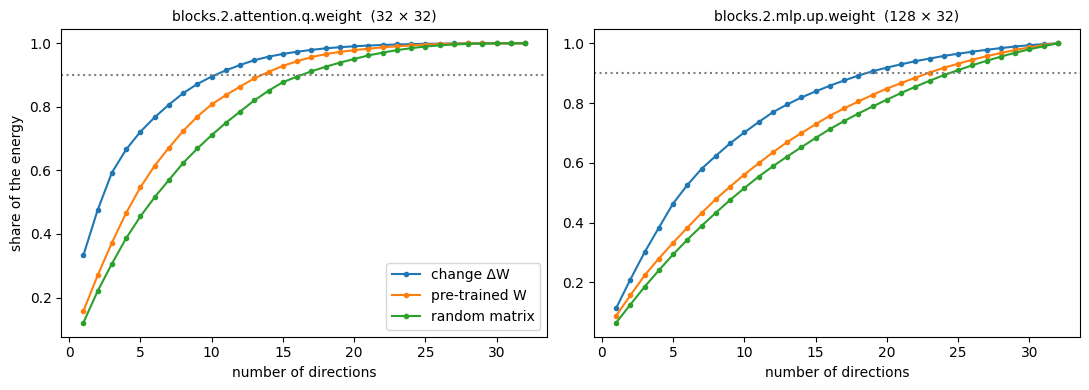

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
before, after = bases[0].state_dict(), fulls[0].state_dict()
for ax, name in zip(axes, ["blocks.2.attention.q.weight", "blocks.2.mlp.up.weight"]):
    W = before[name]
    for label, M in (("change ΔW", after[name] - W), ("pre-trained W", W), ("random matrix", torch.randn(W.shape, generator=torch.Generator().manual_seed(0)))):
        e = energy(M)
        ax.plot(range(1, len(e) + 1), e, marker="o", ms=3, label=label)
    ax.axhline(0.9, color="gray", ls=":")
    ax.set_title(f"{name}  ({W.shape[0]} × {W.shape[1]})", fontsize=10)
    ax.set_xlabel("number of directions")
axes[0].set_ylabel("share of the energy")
axes[0].legend()
plt.tight_layout()
plt.show()

The change is **not** very low-rank in our network, and the table says it plainly. For the matrices of the attention the change $\Delta W$ needs on average 10.4 (the query matrix, $32 \times 32$), 15.4 (keys and values together, $64 \times 32$) and 11.0 directions (the output matrix) to hold 90% of the energy; for the MLP 19.0 and 18.1. The largest possible number is 32 for all of them, so the changes are not close to rank 1 or 2. The random matrices need 16.8, 21.5, 16.5, 24.8 and 25.0 directions and the pre-trained matrices $W$ 14.8, 19.9, 15.9, 23.4 and 22.9. The change is more concentrated than a random matrix (by 38% in the query matrix, 33% in the output matrix, 28% in $W_{KV}$ and about 25% in the MLP) and also more than $W$ itself, as the plot shows for two matrices, but it is a moderate concentration, not a collapse. Another figure that the table gives is the size of the change: $\|\Delta W\| / \|W\|$ is between 0.07 and 0.11, so the fine-tuning moves each matrix by less than a tenth of its norm.

What we can conclude, and what not. **The hypothesis of a low intrinsic rank is not confirmed here in its strong form**: the changes of the *full* fine-tuning use many directions. But this does not say yet that a change of low rank cannot solve the task: the full fine-tuning is not asked to look for the smallest change, only to reduce the loss, and a low-rank change could be enough, perhaps in a different place. This is what we test in the next step by training the thin matrices directly. A reason for caution is that our matrices are only 32 wide, and from this toy we cannot say what happens in a real model, whose matrices are thousands of numbers wide.

## Step 4: training the thin matrices, and what the rank changes

> **A simple example.** To write `anna lives in milan .` in C the network has to learn a handful of new associations: `lives in` becomes one word of C, `milan` becomes its word of C, `she` becomes its pronoun of C, and the same for every drink, job, city and colour of the world. A change of rank 1 is a single direction: all the words are pushed the same way, with a different strength. A change of rank 8 has eight directions to use.
>
> The question of this section is: how much rank does this adaptation need, and in which matrices of the network is it better to put it? The intuition is that the more different things the change has to do at the same time, the more directions it needs, and that a change which is too thin will learn the structure of the new sentences (names in the right places) but not the whole lexicon.

We train the thin matrices directly, with the same 300 pairs and the same 1,000 steps of Step 2. Before the comparison there is a point that is easy to overlook and that changes the results a lot: the **learning rate**. In Step 2 we used $10^{-3}$ for the full fine-tuning without choosing it. With LoRA $B$ starts at zero, so the change grows from nothing and the best learning rate is probably another one. To compare the two methods fairly each has its own search, on a **third world** (validation) that is neither one of the training nor the test world. For LoRA we search at one setting ($r = 8$, attention and MLP) and we keep the value for the other ranks, which is a simplification.

In [12]:
val_c = as_tensor(pairs("C", 1000, 720, [make_world(60)]))         # a third world, to choose the learning rate: the test world is not used here

def sentences(model, data):
    return tinylm.completion_accuracy(model, data, SEP)[0]

def full_network(seed, lr):
    return trained_network(f"full fine-tuning lr={lr:g} seed {seed}",
                           lambda: tinylm.fine_tune(copy.deepcopy(bases[seed]), finetuning_data, SEP, steps=1000, lr=lr, seed=seed))

def lora_network(seed, r, where, lr):
    return trained_network(f"LoRA {'+'.join(where)} r={r} lr={lr:g} seed {seed}",
                           lambda: tinylm.fine_tune(tinylm.add_lora(copy.deepcopy(bases[seed]), r, where, seed=seed), finetuning_data, SEP, steps=1000, lr=lr, seed=seed))

grids = {"full fine-tuning": ((3e-4, 1e-3, 3e-3), lambda s, lr: full_network(s, lr)),
         "LoRA r=8, attention + MLP": ((1e-3, 3e-3, 1e-2, 3e-2), lambda s, lr: lora_network(s, 8, ("attention", "mlp"), lr))}
search = {}
for method, (lrs, make) in grids.items():
    search[method] = pd.DataFrame({f"seed {s}": [sentences(make(s, lr), val_c) for lr in lrs] for s in SEEDS}, index=[f"{lr:g}" for lr in lrs])
    search[method]["mean"] = search[method].mean(axis=1)
    print(f"\n{method}: sentences right on the validation world, by learning rate")
    print(search[method].round(3).to_string())

FULL_LR = float(search["full fine-tuning"]["mean"].idxmax())
LORA_LR = float(search["LoRA r=8, attention + MLP"]["mean"].idxmax())
print(f"\nchosen: full fine-tuning {FULL_LR:g}, LoRA {LORA_LR:g}")

full fine-tuning lr=0.0003 seed 0: 60,021 parameters, 60,021 trained, loaded from the cache


full fine-tuning lr=0.001 seed 0: 60,021 parameters, 60,021 trained, loaded from the cache


full fine-tuning lr=0.003 seed 0: 60,021 parameters, 60,021 trained, loaded from the cache


full fine-tuning lr=0.0003 seed 1: 60,021 parameters, 60,021 trained, loaded from the cache


full fine-tuning lr=0.001 seed 1: 60,021 parameters, 60,021 trained, loaded from the cache


full fine-tuning lr=0.003 seed 1: 60,021 parameters, 60,021 trained, loaded from the cache


... (5 outputs left out)

LoRA attention+mlp r=8 lr=0.003 seed 1: 77,429 parameters, 17,408 trained, loaded from the cache


LoRA attention+mlp r=8 lr=0.01 seed 1: 77,429 parameters, 17,408 trained, loaded from the cache


LoRA attention+mlp r=8 lr=0.03 seed 1: 77,429 parameters, 17,408 trained, loaded from the cache



LoRA r=8, attention + MLP: sentences right on the validation world, by learning rate
       seed 0  seed 1   mean
0.001   0.764   0.085  0.424
0.003   0.899   0.272  0.586
0.01    0.932   0.755  0.844
0.03    0.000   0.841  0.420

chosen: full fine-tuning 0.003, LoRA 0.01


The learning rate changes the picture a lot, for both methods. For the **full fine-tuning** $3 \cdot 10^{-4}$ is too low (mean 0.508, and the seed 1 gets only 0.122), $10^{-3}$, the value that we used in Step 2 without choosing it, gives 0.862, and $3 \cdot 10^{-3}$ gives 0.913. So the value of Step 2 was not the best one, and the best is at the edge of the grid: a larger one could be better, and we did not try it. For **LoRA** the values are lower for the small learning rates and the best is larger: $10^{-3}$ gives 0.424, $3 \cdot 10^{-3}$ gives 0.586, $10^{-2}$ gives 0.844. At $3 \cdot 10^{-2}$ the two seeds behave in opposite ways: the seed 0 writes no sentence right (0.000) and the seed 1 gets its best value (0.841); we did not look at why the first fails. We keep $10^{-2}$, about three times the learning rate of the full fine-tuning. The choice rests on the mean of two seeds, and with other seeds another value could come out.

Two consequences. First, the accuracy of the full fine-tuning that we compare with LoRA below is that of $3 \cdot 10^{-3}$, not the one of Step 2. Second, the sensitivity of LoRA to the learning rate (from 0.42 to 0.84 on the validation world between $10^{-3}$ and $10^{-2}$) is part of its cost in practice: a comparison with the same learning rate for the two methods would have favoured one of them.

Now the rank. For the two choices of matrices (the attention alone, and the attention with the MLP) and for $r = 1, 2, 4, 8, 16$ we train the thin matrices with the learning rate chosen above, on both seeds, and we compare with the full fine-tuning at its own learning rate. We test on the world of the test (never used so far for choices).

In [13]:
RANKS = (1, 2, 4, 8, 16)
rows, per_seed = [], {}
for where in (("attention",), ("attention", "mlp")):
    for r in RANKS:
        models = [lora_network(s, r, where, LORA_LR) for s in SEEDS]
        results = pd.DataFrame([evaluate(m) for m in models])
        per_seed[(" + ".join(where), r)] = results["A→C sentences"].tolist()
        rows.append({"matrices": " + ".join(where), "rank r": r, "trainable parameters": tinylm.n_trainable(models[0]), "share of the pre-trained network": tinylm.n_trainable(models[0]) / bases[0].n_parameters(), **results.mean().to_dict()})
full_models = [full_network(s, FULL_LR) for s in SEEDS]
full_results = pd.DataFrame([evaluate(m) for m in full_models])
rows.append({"matrices": "all (full fine-tuning)", "rank r": None, "trainable parameters": full_models[0].n_parameters(), "share of the pre-trained network": 1.0, **full_results.mean().to_dict()})
ranks = pd.DataFrame(rows)
ranks.insert(5, "seed 0 / seed 1", [" / ".join(f"{x:.2f}" for x in v) for v in list(per_seed.values()) + [full_results["A→C sentences"].tolist()]])
ranks.drop(columns=["A→B sentences"]).style.format({"rank r": "{:.0f}", "trainable parameters": "{:,}", "share of the pre-trained network": "{:.1%}", "A→C sentences": "{:.3f}", "A→C words": "{:.3f}", "plain-text loss": "{:.2f}"}, na_rep="").hide(axis="index")

LoRA attention r=1 lr=0.01 seed 0: 60,917 parameters, 896 trained, loaded from the cache
LoRA attention r=1 lr=0.01 seed 1: 60,917 parameters, 896 trained, loaded from the cache


LoRA attention r=2 lr=0.01 seed 0: 61,813 parameters, 1,792 trained, loaded from the cache
LoRA attention r=2 lr=0.01 seed 1: 61,813 parameters, 1,792 trained, loaded from the cache


LoRA attention r=4 lr=0.01 seed 0: 63,605 parameters, 3,584 trained, loaded from the cache
LoRA attention r=4 lr=0.01 seed 1: 63,605 parameters, 3,584 trained, loaded from the cache


LoRA attention r=8 lr=0.01 seed 0: 67,189 parameters, 7,168 trained, loaded from the cache
LoRA attention r=8 lr=0.01 seed 1: 67,189 parameters, 7,168 trained, loaded from the cache


LoRA attention r=16 lr=0.01 seed 0: 74,357 parameters, 14,336 trained, loaded from the cache
LoRA attention r=16 lr=0.01 seed 1: 74,357 parameters, 14,336 trained, loaded from the cache


LoRA attention+mlp r=1 lr=0.01 seed 0: 62,197 parameters, 2,176 trained, loaded from the cache
LoRA attention+mlp r=1 lr=0.01 seed 1: 62,197 parameters, 2,176 trained, loaded from the cache


... (2 outputs left out)

LoRA attention+mlp r=8 lr=0.01 seed 0: 77,429 parameters, 17,408 trained, loaded from the cache
LoRA attention+mlp r=8 lr=0.01 seed 1: 77,429 parameters, 17,408 trained, loaded from the cache


LoRA attention+mlp r=16 lr=0.01 seed 0: 94,837 parameters, 34,816 trained, loaded from the cache
LoRA attention+mlp r=16 lr=0.01 seed 1: 94,837 parameters, 34,816 trained, loaded from the cache


full fine-tuning lr=0.003 seed 0: 60,021 parameters, 60,021 trained, loaded from the cache
full fine-tuning lr=0.003 seed 1: 60,021 parameters, 60,021 trained, loaded from the cache


matrices,rank r,trainable parameters,share of the pre-trained network,A→C sentences,seed 0 / seed 1,A→C words,plain-text loss
attention,1,896,1.5%,0.025,0.05 / 0.00,0.773,1.07
attention,2,"1,792",3.0%,0.102,0.20 / 0.00,0.870,1.12
attention,4,"3,584",6.0%,0.271,0.45 / 0.09,0.921,1.19
attention,8,"7,168",11.9%,0.538,0.67 / 0.40,0.945,1.54
attention,16,"14,336",23.9%,0.678,0.76 / 0.60,0.961,1.77
attention + mlp,1,"2,176",3.6%,0.276,0.51 / 0.04,0.908,1.22
attention + mlp,2,"4,352",7.3%,0.681,0.79 / 0.58,0.968,1.34
attention + mlp,4,"8,704",14.5%,0.613,0.89 / 0.34,0.967,1.47
attention + mlp,8,"17,408",29.0%,0.842,0.92 / 0.77,0.985,1.70
attention + mlp,16,"34,816",58.0%,0.899,0.92 / 0.88,0.990,1.82


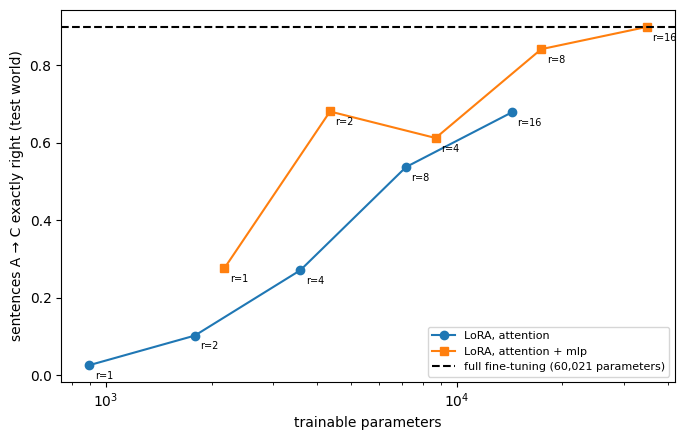

In [14]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for where, marker in (("attention", "o"), ("attention + mlp", "s")):
    part = ranks[ranks["matrices"] == where]
    ax.plot(part["trainable parameters"], part["A→C sentences"], marker=marker, label=f"LoRA, {where}")
    for _, row in part.iterrows():
        ax.annotate(f"r={int(row['rank r'])}", (row["trainable parameters"], row["A→C sentences"]), textcoords="offset points", xytext=(4, -10), fontsize=7)
ax.axhline(ranks.iloc[-1]["A→C sentences"], color="k", ls="--", label=f"full fine-tuning ({int(ranks.iloc[-1]['trainable parameters']):,} parameters)")
ax.set_xscale("log")
ax.set_xlabel("trainable parameters")
ax.set_ylabel("sentences A → C exactly right (test world)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The numbers of the table are on the **test world**, the mean of two seeds with the two values in the column "seed 0 / seed 1".

* **Attention only**: the sentences right go from 2.5% ($r = 1$) to 10.2%, 27.1%, 53.8% and 67.8% ($r = 16$), always below the full fine-tuning (90.0%, with 0.95 and 0.85 in the two seeds).
* **Attention and MLP**: 27.6% ($r = 1$), 68.1%, 61.3%, 84.2% and **89.9% at $r = 16$**, the same as the full fine-tuning. The drop from $r = 2$ to $r = 4$ is not a property of the method: it comes from the seed 1 (0.58 and then 0.34), while the seed 0 goes from 0.79 to 0.89. With two seeds the single points are not reliable, the trend is.
* **Where to put the change matters as much as the rank.** The MLP matrices with $r = 2$ (4,352 trainable parameters, 7.3% of the network) get 68.1%, the same as the matrices of the attention alone with $r = 16$ (14,336 parameters, 23.9%, 67.8%): three times fewer parameters for the same result. We did not test why the MLP is worth more here.
* **The words right** are high even where the sentences are not: with the attention alone and $r = 1$ they are 77.3% (the pre-trained network, which writes B, had 40.8%), and they are above 90% from $r = 4$ on. A change that is too thin moves the network from writing B to writing something close to C, with most of the words right and a few sentences completely right.

**What it costs in the toy.** The rank that brings LoRA to the full fine-tuning ($r = 8$ to $16$, with the MLP) is of the same size as the number of directions that Step 3 counted for 90% of the energy of $\Delta W$ (10 to 19). But with matrices of 32 numbers this means 17,408 to 34,816 trainable parameters, **29% to 58% of the network**: in our toy LoRA matches the full fine-tuning, it does not make it cheap. The economy of the method is the ratio $r(d_{in} + d_{out}) / (d_{in} d_{out})$, and it needs wide matrices; we cannot show it here and we count it in the notebook only as arithmetic.

**What it does not give.** The loss on plain texts is higher for LoRA with a high rank (1.70 at $r = 8$ and 1.82 at $r = 16$, attention and MLP) than for the full fine-tuning (1.34), and the pre-trained network had 0.89: with the thin matrices active, the network has not lost less of its old ability than with the full fine-tuning. We did not test the reason (the larger learning rate is one candidate). What LoRA keeps intact is the matrix $W$, and this is the subject of the next step.

## Step 5: switching the adapter, and the merge

> **A simple example.** The network that translates from A to C is the pre-trained network plus a small change in each matrix: $W$ becomes $W + BA$. The matrices $W$ never change, and the adapter (the $A$ and $B$ of every layer) is a small file. With the adapter **on** the network writes C after `source <sep>`; with the adapter **off** it is again the pre-trained translator A → B, exactly. With the full fine-tuning of Step 2 we would have had to keep a copy of the whole network to get the old behavior back.
>
> The question of this section is: what does it cost to run the network with the adapter, and can we fold the change into the matrices (the "merge") so that it runs as fast as the original? The intuition is that $BA$ is a table of the same size as $W$, so it can be added to $W$ once and for all.

In [15]:
test_tasks = {"A→B": test_b, "A→C": test_c}

RANK, WHERE = 8, ("attention", "mlp")
adapters = {s: tinylm.adapter_state(lora_network(s, RANK, WHERE, LORA_LR)) for s in SEEDS}
print(f"{sum(v.numel() for v in adapters[0].values()):,} numbers in the adapter")

LoRA attention+mlp r=8 lr=0.01 seed 0: 77,429 parameters, 17,408 trained, loaded from the cache
LoRA attention+mlp r=8 lr=0.01 seed 1: 77,429 parameters, 17,408 trained, loaded from the cache
17,408 numbers in the adapter


The adapter is what `adapter_state` returns: the $A$ and $B$ of every layer, 17,408 numbers (for $r = 8$, attention and MLP), and nothing else. We build **one** network, the pre-trained one with its LoRA layers, and we change only the adapter: first off, then on. In each case we test the two tasks, A → B (what the network was pre-trained for) and A → C.

In [16]:
def task_row(model):
    return {task: sentences(model, data) for task, data in test_tasks.items()}

def serving_row(seed, state):
    # one network with LoRA layers; the adapter is `state`, or off
    network = tinylm.add_lora(copy.deepcopy(bases[seed]), RANK, WHERE, seed=seed)
    if state is None:
        tinylm.set_adapter(network, False)
    else:
        tinylm.load_adapter(network, state)
    return network, task_row(network)

states = {"adapter off": lambda s: None, "adapter on": lambda s: adapters[s]}
table = pd.DataFrame({name: pd.DataFrame([serving_row(s, pick(s))[1] for s in SEEDS]).mean() for name, pick in states.items()}).T
print("sentences exactly right, mean of 2 seeds")
print(table.round(3).to_string())

network, _ = serving_row(0, None)
sample = test_b[:8, :30]
print("\nlargest difference between the outputs of the pre-trained network and of the network with the adapter off:", (network(sample) - bases[0](sample)).abs().max().item())

sentences exactly right, mean of 2 seeds
               A→B    A→C
adapter off  0.994  0.000
adapter on   0.000  0.842



largest difference between the outputs of the pre-trained network and of the network with the adapter off: 0.0


The table is the mean of two seeds. With the adapter **off** the network is the pre-trained one: A → B 99.4%, A → C zero, and the largest difference between its outputs and those of the pre-trained network is 0.0. Nothing of the base was lost, unlike the full fine-tuning of Step 2, after which A → B was gone for good. With the adapter **on** the network gets 84.2% of the A → C sentences (0.918 and 0.766 in the two seeds) and A → B goes to zero: the old behavior is not kept *together* with the new one (the input `source <sep>` is the same, and the network writes C, as in Step 2). The difference is that the old behavior comes back by switching the adapter off.

**The merge.** With the adapter on, every LoRA layer computes $Wx + BAx$: the product of $W$ with $x$, plus two thin products (first $Ax$, then $B(Ax)$). At first sight we cannot add $BA$ to $W$, because $A$ and $B$ are thin. But *the product of the two is not thin*. Look at the shapes:

$$\underbrace{B}_{d_{out} \times r}\;\underbrace{A}_{r \times d_{in}} \;=\; \underbrace{BA}_{d_{out} \times d_{in}}$$

$BA$ is a table of $d_{out} \times d_{in}$ numbers, the same shape as $W$. What is small is the number of numbers that we *train* ($A$ and $B$), and the rank of $BA$ (at most $r$: its rows are combinations of the $r$ rows of $A$), not its size. So $W + BA$ is a sum of two tables of the same shape, and since matrix products are linear,

$$Wx + BAx = (W + BA)\,x.$$

We compute $W + BA$ once, put it in place of $W$ and delete $A$ and $B$ (`merge_lora`; with $\alpha = r$ the factor $\alpha / r$ is 1). The network is again a plain network with the parameters of the original, but it is the network of the task. Here are the shapes for one matrix of our network, and the check of the equality on one input:

In [17]:
name = next(k for k in adapters[0] if k.endswith(".A"))[:-2]          # the first layer with an adapter
W, A, B = bases[0].state_dict()[name + ".weight"], adapters[0][name + ".A"], adapters[0][name + ".B"]
print(f"{name}:  W {tuple(W.shape)},  B {tuple(B.shape)},  A {tuple(A.shape)},  B @ A {tuple((B @ A).shape)}")
print(f"numbers: W {W.numel():,},  A and B together {A.numel() + B.numel():,},  rank of B @ A: {torch.linalg.matrix_rank(B @ A).item()} (at most r = {RANK})")
x = torch.randn(5, W.shape[1])
print("largest difference between W x + B A x and (W + B A) x:", ((x @ W.T + x @ A.T @ B.T) - x @ (W + B @ A).T).abs().max().item())

blocks.0.attention.q:  W (32, 32),  B (32, 8),  A (8, 32),  B @ A (32, 32)
numbers: W 1,024,  A and B together 512,  rank of B @ A: 8 (at most r = 8)
largest difference between W x + B A x and (W + B A) x: 3.5762786865234375e-07


The change $BA$ has the shape of $W$ and a rank of at most 8 (the rank of a $32 \times 32$ matrix could be 32); adding it to $W$ is an ordinary sum, and the two ways of computing the output agree up to the rounding of the floating point numbers. Now we do it for every layer of the network and we measure the time of the three networks on 64 texts.

In [18]:
import timeit

adapted, _ = serving_row(0, adapters[0])
merged = tinylm.merge_lora(adapted)
sample = test_c[:8, :30]
print("largest difference between the outputs of the network with the adapter and of the merged one:", (merged(sample) - adapted(sample)).abs().max().item())
print(f"parameters: pre-trained {bases[0].n_parameters():,}, with the adapter {adapted.n_parameters():,}, merged {merged.n_parameters():,}")
print("\nsentences exactly right (seed 0), on the two tasks:")
print(pd.DataFrame({"pre-trained": task_row(bases[0]), "with the adapter": task_row(adapted), "merged": task_row(merged)}).T.round(3).to_string())

batch = test_c[:64]
with torch.no_grad():
    for name, model in (("pre-trained", bases[0]), ("with the adapter", adapted), ("merged", merged)):
        print(f"time of a forward pass on 64 texts, {name}: {min(timeit.repeat(lambda: model(batch), number=20, repeat=5)) / 20 * 1000:.2f} ms")

largest difference between the outputs of the network with the adapter and of the merged one: 1.3589859008789062e-05
parameters: pre-trained 60,021, with the adapter 77,429, merged 60,021

sentences exactly right (seed 0), on the two tasks:


                    A→B    A→C
pre-trained       0.995  0.000
with the adapter  0.000  0.918
merged            0.000  0.918


time of a forward pass on 64 texts, pre-trained: 2.98 ms


time of a forward pass on 64 texts, with the adapter: 5.44 ms


time of a forward pass on 64 texts, merged: 3.10 ms


The merged network gives the same outputs as the network with the adapter: the largest difference is $1.4 \cdot 10^{-5}$, the rounding of the floating point numbers, and the sentences right are the same on both tasks (0.918 on A → C and 0.000 on A → B for the seed 0). The merge does not add A → C to the old behavior: the merged network *is* the network with the adapter on, so it has learned A → C and, with the same input `source <sep>`, it has lost A → B, exactly like the network with the adapter on. It is not a network that does both tasks. Its parameters are those of the original network, 60,021, against 77,429 with the adapter (the original plus the 17,408 of the adapter).

On our machine and on 64 texts a forward pass takes about 3 ms in the pre-trained network, about 5.5 ms with the adapter on and about 3 ms merged (the times change a little from one run to the other): in the toy the adapter makes the pass about 75-80% slower, and the merged network costs nothing more than the original. The 75-80% depends on our small matrices: the work added by the adapter is $r\,(d_{in} + d_{out})$ multiplications for each vector against $d_{in}\,d_{out}$ of the matrix, a ratio that decreases as the matrices get wider (this is arithmetic, we did not measure it). The price of the merge is that, once the change is mixed into $W$, we cannot switch the adapter off any more: to get A → B back we need a copy of the original $W$ or to subtract the same $BA$ (up to the rounding).

What is left to count is the **storage**: one copy of the whole network for each task, against the pre-trained network once and one adapter for each task. We trained a single adapter; for the other tasks we assume that they have the same size (this is arithmetic, not an experiment).

In [19]:
base_size, adapter_size = bases[0].n_parameters(), sum(v.numel() for v in adapters[0].values())
storage = pd.DataFrame({"tasks": [1, 2, 5, 10, 100]})
storage["a full copy for each task"] = storage["tasks"] * base_size
storage["pre-trained network + one adapter for each task"] = base_size + storage["tasks"] * adapter_size
storage["adapters / full copies"] = storage["pre-trained network + one adapter for each task"] / storage["a full copy for each task"]
storage.style.format({"a full copy for each task": "{:,}", "pre-trained network + one adapter for each task": "{:,}", "adapters / full copies": "{:.2f}"}).hide(axis="index")

tasks,a full copy for each task,pre-trained network + one adapter for each task,adapters / full copies
1,"60,021","77,429",1.29
2,"120,042","94,837",0.79
5,"300,105","147,061",0.49
10,"600,210","234,101",0.39
100,"6,002,100","1,800,821",0.30


For **one** task the adapter is more expensive than the copy: 77,429 numbers against 60,021 (the ratio 1.29), since the adapter alone is 17,408 numbers, 29.0% of the network. From two tasks on the adapters win: 0.79 with 2 tasks, 0.49 with 5, 0.39 with 10 and 0.30 with 100. The ratio cannot go below the size of one adapter over the size of the network, 0.29. In the toy the saving is modest because the adapter is almost a third of the network; the same count for a real network, which depends on the shape of its matrices, is in the next step.

## Step 6: what LoRA costs in a real network

> **A simple example.** The matrix $W_Q$ of our network is a table of $32 \times 32$ numbers, and the matrices of its MLP are $32 \times 128$. In GPT-2, the network of L1.4, the table that produces the queries, the keys and the values of the attention in a single product has 768 rows and 2,304 columns. A change of rank 8 of that table is written with $8 \times (768 + 2304)$ numbers, and the table has $768 \times 2304$.
>
> The question of this section is: how many parameters would LoRA train in a real network, and is the saving that we could not show in the toy there? The intuition is that the cost of the change grows with the *sum* of the two sides of the matrix and the cost of the matrix with their *product*, so the wider the matrices, the larger the saving.

In [20]:
from transformers import AutoTokenizer, AutoModelForCausalLM

try:
    gpt2 = AutoModelForCausalLM.from_pretrained("gpt2", local_files_only=True).eval()
except OSError:                                                      # not in the cache: download it
    gpt2 = AutoModelForCausalLM.from_pretrained("gpt2").eval()

block = gpt2.transformer.h[0]
shapes = {name: tuple(m.weight.shape) for name, m in block.named_modules() if hasattr(m, "weight") and m.weight.dim() == 2}
print("the matrices of one block of GPT-2 (input size, output size):", shapes)
print(f"blocks: {gpt2.config.n_layer}, parameters: {sum(p.numel() for p in gpt2.parameters()):,}")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

the matrices of one block of GPT-2 (input size, output size): {'attn.c_attn': (768, 2304), 'attn.c_proj': (768, 768), 'mlp.c_fc': (768, 3072), 'mlp.c_proj': (3072, 768)}
blocks: 12, parameters: 124,439,808


With the shapes of the matrices the count is an arithmetic one: for each matrix, $r\,(d_{in} + d_{out})$ numbers, for each block. To be sure that the formula is the one of a real network we also build the network with a low-rank change in the four matrices of every block (with a few lines, since the layers of GPT-2 are not the `Linear` layers of our network), and we check that the number of trainable parameters is the one of the formula and that, as in Step 3, at the start the network is exactly GPT-2.

In [21]:
total = sum(p.numel() for p in gpt2.parameters())
ATTENTION, BOTH = ("attn.c_attn", "attn.c_proj"), ("attn.c_attn", "attn.c_proj", "mlp.c_fc", "mlp.c_proj")

def lora_size(r, names):
    return gpt2.config.n_layer * sum(r * (shape[0] + shape[1]) for name, shape in shapes.items() if name in names)

rows = []
for names, label in ((ATTENTION, "attention"), (BOTH, "attention + MLP")):
    for r in (1, 4, 8, 16):
        n = lora_size(r, names)
        rows.append({"matrices": label, "rank r": r, "trainable parameters": n, "share of GPT-2": n / total, "an adapter in float32 (MB)": 4 * n / 1e6})
print(f"a full copy of GPT-2 in float32: {4 * total / 1e6:,.1f} MB")
pd.DataFrame(rows).style.format({"trainable parameters": "{:,}", "share of GPT-2": "{:.2%}", "an adapter in float32 (MB)": "{:.1f}"}).hide(axis="index")

a full copy of GPT-2 in float32: 497.8 MB


matrices,rank r,trainable parameters,share of GPT-2,an adapter in float32 (MB)
attention,1,"55,296",0.04%,0.2
attention,4,"221,184",0.18%,0.9
attention,8,"442,368",0.36%,1.8
attention,16,"884,736",0.71%,3.5
attention + MLP,1,"147,456",0.12%,0.6
attention + MLP,4,"589,824",0.47%,2.4
attention + MLP,8,"1,179,648",0.95%,4.7
attention + MLP,16,"2,359,296",1.90%,9.4


In [22]:
class LoRAConv1D(torch.nn.Module):
    # the same layer as tinylm.LoRALinear for the Conv1D layers of GPT-2 (they store the matrix as input size x output size)
    def __init__(self, base, r):
        super().__init__()
        self.base = base
        d_in, d_out = base.weight.shape
        self.A = torch.nn.Parameter(torch.randn(r, d_in) / d_in ** 0.5)
        self.B = torch.nn.Parameter(torch.zeros(d_out, r))

    def forward(self, x):
        return self.base(x) + x @ self.A.T @ self.B.T

adapted = copy.deepcopy(gpt2)
for p in adapted.parameters():
    p.requires_grad_(False)
for h in adapted.transformer.h:
    for module, names in ((h.attn, ("c_attn", "c_proj")), (h.mlp, ("c_fc", "c_proj"))):
        for name in names:
            setattr(module, name, LoRAConv1D(getattr(module, name), 8))

tokenizer = AutoTokenizer.from_pretrained("gpt2", local_files_only=True)
ids = tokenizer("anna lives in milan and she drinks", return_tensors="pt").input_ids
with torch.no_grad():
    print("largest difference between the logits of GPT-2 and of GPT-2 with LoRA at the start:", (adapted(ids).logits - gpt2(ids).logits).abs().max().item())
print(f"trainable parameters of the network: {tinylm.n_trainable(adapted):,}; formula for r = 8, attention + MLP: {lora_size(8, BOTH):,}")

largest difference between the logits of GPT-2 and of GPT-2 with LoRA at the start: 0.0
trainable parameters of the network: 1,179,648; formula for r = 8, attention + MLP: 1,179,648


A block of GPT-2 has four matrices: the one that produces the queries, the keys and the values together ($768 \times 2304$), the output of the attention ($768 \times 768$), and the two of the MLP ($768 \times 3072$ and $3072 \times 768$); the network has 12 blocks and 124,439,808 parameters. A change of rank 8 in the four matrices of every block has **1,179,648 parameters, 0.95% of GPT-2** (4.7 MB in float32, against 497.8 MB for a full copy). With the attention alone it is 442,368 (0.36%); with $r = 1$ on the attention, 55,296 (0.04%); with $r = 16$ on attention and MLP, 2,359,296 (1.90%).

The network built with these layers has exactly 1,179,648 trainable parameters, as the formula says, and at the start its logits are the same as those of GPT-2 (largest difference 0.0). What this shows is the count and the construction, **not** that LoRA works on GPT-2: we did not train it.

The comparison with the toy is the one of the intuition of the section. With $r = 8$ the change of a $32 \times 32$ matrix of our network has half of the numbers of the matrix ($8 \times 64$ against 1,024), and the change of the $768 \times 768$ matrix of GPT-2 has 2.1% ($8 \times 1536$ against 589,824). For the whole network, attention and MLP with $r = 8$ were 29.0% in the toy and are 0.95% in GPT-2: the saving that we could not show is there, and it comes from the width of the matrices.

## What changes with the real models, and the limits of this notebook

**What this notebook did not show.**

* **The savings of LoRA.** In the toy the best settings of LoRA were 29% to 58% of the network, so the method matched the full fine-tuning without making it cheap. The count of the previous step is arithmetic, not an experiment: we did not train LoRA on GPT-2.
* **The task.** The tasks of the notebook are translations between the languages of a toy world, where the whole task is a small lexicon and a word order. We do not know how the results on the rank, on the matrices and on the learning rate carry over to other tasks or to a larger network.
* **The choices.** Two seeds; a single number of pairs (300) and of steps (1,000); the learning rate of LoRA searched at one setting and then kept for all the ranks; the learning rate of the full fine-tuning at the edge of the grid; $\alpha = r$ always; ranks up to 16 in matrices of 32. Differences of a few points between single runs are not an indication.

**Other methods** that adapt a model by training few parameters, which we have not implemented: small modules inserted in the blocks (adapters, Houlsby et al., 2019), vectors that are added to the text or to the attention of a frozen network (prefix tuning, Li and Liang, 2021; prompt tuning, Lester et al., 2021), and LoRA on a network whose weights are stored with fewer bits (QLoRA, Dettmers et al., 2023).

**From fine-tuning to the assistant (L1.6).** In this notebook what changed from a network to the other was the *examples*: pairs of sentences in two languages. The method does not depend on them. In the next notebook the examples are instructions with the answers that we want, and then pairs of answers of which one is preferred by a person: instruction tuning, RLHF and DPO. LoRA is one of the ways to train a network on such examples without changing all its weights.

## Conclusions

What we saw in the toy (two seeds; the numbers are those of the saved networks, and training them again from scratch on our machine gave the same ones):

1. **A pre-trained network does not know a task that it has never seen, even if it is a small variation of one it knows.** The network that translates from A to B writes B when asked for C (0% of the sentences for A → C, 61.7% of its words in B).
2. **The full fine-tuning works with few examples, and it has costs.** With 300 pairs it writes 95% and 85% of the sentences right (two seeds, learning rate chosen on a validation world), against 3.4% and 13.4% of the same network trained from scratch. But it needs memory for the parameters, their gradients and the averages of the optimizer, it produces a copy of the network for each task, and the old behavior is replaced.
3. **The change that the full fine-tuning makes is not very low-rank in our network** (10 to 19 directions out of 32 for 90% of the energy of $\Delta W$, against 17 to 25 of a random matrix), and a low-rank change is nonetheless enough: LoRA on the attention and the MLP matches the full fine-tuning at $r = 16$ (89.9% against 90.0%), but with 58% of the parameters; $r = 8$ gets 84.2% with 29%. With the attention alone the best was 67.8% ($r = 16$). Where the change is put matters as much as the rank.
4. **The learning rate matters more than it seems** and not in the same way for the two methods: LoRA needed about three times the learning rate of the full fine-tuning, and at ten times it was unstable in one seed.
5. **With LoRA the network is not changed: the adapter is added to it.** With the adapter off the outputs are exactly those of the pre-trained network; and an adapter can be merged into the matrices with the same outputs, the same number of parameters as the original and the same speed. For one task the adapter is more expensive than a copy; it pays from two tasks on.
6. **The saving depends on the width of the matrices.** In GPT-2, with $r = 8$ on the four matrices of every block, the adapter has 1,179,648 numbers, 0.95% of the network, against 29.0% in the toy.

### References

* Hu, E. J., Shen, Y., Wallis, P., et al. (2021). *LoRA: Low-Rank Adaptation of Large Language Models.* arXiv:2106.09685.
* Aghajanyan, A., Gupta, S., Zettlemoyer, L. (2021). *Intrinsic Dimensionality Explains the Effectiveness of Language Model Fine-Tuning.* ACL 2021.
* Houlsby, N., Giurgiu, A., Jastrzebski, S., et al. (2019). *Parameter-Efficient Transfer Learning for NLP.* ICML 2019.
* Li, X. L., Liang, P. (2021). *Prefix-Tuning: Optimizing Continuous Prompts for Generation.* ACL 2021.
* Lester, B., Al-Rfou, R., Constant, N. (2021). *The Power of Scale for Parameter-Efficient Prompt Tuning.* EMNLP 2021.
* Dettmers, T., Pagnoni, A., Holtzman, A., Zettlemoyer, L. (2023). *QLoRA: Efficient Finetuning of Quantized LLMs.* NeurIPS 2023.